# Part D · The three health figures

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 5

A health organisation tracks an outbreak alongside four socio-economic indicators. Pairwise charts hide the
interactions, and the regional map plots raw counts. Three figures, each exported at 300 dpi with
`vizlib.save_fig()`:

| Figure | File |
|---|---|
| D1 · Four-variable bubble chart | [`charts/partD_bubble.png`](charts/partD_bubble.png) |
| D2 · Parallel coordinates | [`charts/partD_pcp.png`](charts/partD_pcp.png) |
| D3 · Normalized choropleth + counts | [`charts/partD_choropleth.png`](charts/partD_choropleth.png) |

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import geolib as g
from vizlib import PALETTE, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]
SOURCE = "Source: synthetic course data, CDB601220 Week 5 (downloaded 2026-10-24)."
hi = pd.read_csv(DATA / "health_indicators.csv")

## D1 · The four-variable bubble chart

| Channel | Variable | Why this channel |
|---|---|---|
| x position | `gdp_pc`, **log scale** | The most precise channel goes to the driver. The spread is multiplicative ($283 to $120,219) |
| y position | `healthcare_access` | The outcome, also needing precise comparison. Bounded 0–100, so the axis is 0–100 |
| area | `pop_m` | Context, read roughly. **Area**, linear in population, 12–1,500 pt² (Part B.1) |
| hue | `region` | Identity, not amount. Six categories, which is within the ~7 hues the eye can keep apart |

**The outlier.** Aldonia ($120,219, 9.2× the next country) is **kept and labelled**. On a log axis it sits
0.97 decades to the right, not off the chart. It's a real small, rich country, and dropping it would be
editing the data to tidy the picture.

r(log10 gdp, access) = 0.83 with Aldonia, 0.86 without


'charts\\partD_bubble.png'

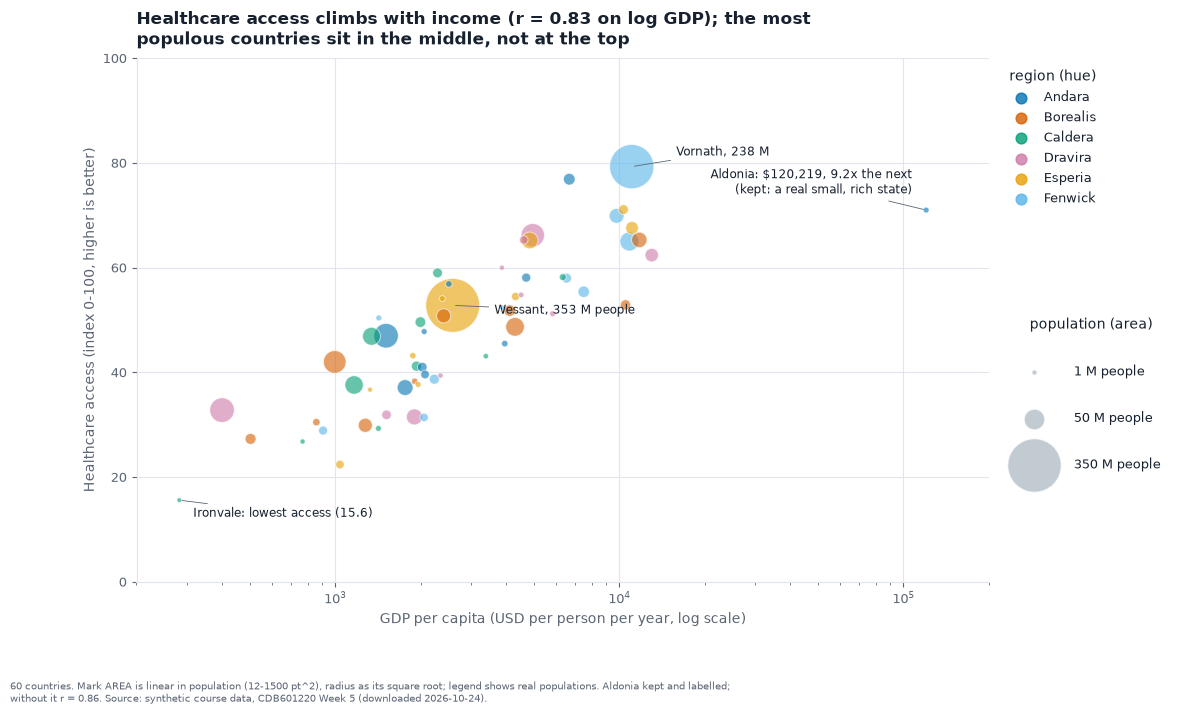

In [2]:
REGION_COLOUR = dict(zip(sorted(hi.region.unique()),
                         ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]))
LO, HI = 12, 1500


def area_pt2(pop):
    return LO + (HI - LO) * (pop - hi.pop_m.min()) / (hi.pop_m.max() - hi.pop_m.min())


r_ga = np.corrcoef(np.log10(hi.gdp_pc), hi.healthcare_access)[0, 1]
r_ga_wo = np.corrcoef(np.log10(hi.gdp_pc.drop(hi.gdp_pc.idxmax())), hi.healthcare_access.drop(hi.gdp_pc.idxmax()))[0, 1]
print(f"r(log10 gdp, access) = {r_ga:.2f} with Aldonia, {r_ga_wo:.2f} without")

fig, ax = plt.subplots(figsize=(11, 6.8))
order = hi.sort_values("pop_m", ascending=False)   # big bubbles first, so small ones sit on top
ax.scatter(order.gdp_pc, order.healthcare_access, s=area_pt2(order.pop_m),
           c=order.region.map(REGION_COLOUR), alpha=0.6, edgecolor="white", linewidth=0.7)
ax.set_xscale("log")
ax.set_xlim(200, 200_000)
ax.set_ylim(0, 100)
ax.set_xlabel("GDP per capita (USD per person per year, log scale)")
ax.set_ylabel("Healthcare access (index 0-100, higher is better)")

labels = {"Aldonia": (-10, 12, "right"), "Wessant": (30, -6, "left"), "Vornath": (32, 8, "left"),
          "Ironvale": (10, -12, "left")}
notes = {"Aldonia": "Aldonia: $120,219, 9.2x the next\n(kept: a real small, rich state)",
         "Wessant": "Wessant, 353 M people", "Vornath": "Vornath, 238 M", "Ironvale": "Ironvale: lowest access (15.6)"}
for c, (dx, dy, ha) in labels.items():
    row = hi[hi.country == c].iloc[0]
    ax.annotate(notes[c], (row.gdp_pc, row.healthcare_access), xytext=(dx, dy), textcoords="offset points",
                ha=ha, fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=SOFT, lw=0.6))

hue_handles = [ax.scatter([], [], s=60, color=col, alpha=0.8, label=reg) for reg, col in REGION_COLOUR.items()]
leg1 = ax.legend(handles=hue_handles, title="region (hue)", loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.add_artist(leg1)
size_handles = [ax.scatter([], [], s=area_pt2(v), color=GREY, alpha=0.6, edgecolor="white", label=f"{v:g} M people")
                for v in (1, 50, 350)]
ax.legend(handles=size_handles, title="population (area)", loc="upper left", bbox_to_anchor=(1.01, 0.55),
          labelspacing=2.6, borderpad=1.4, handletextpad=2.2)
ax.set_title(textwrap.fill(f"Healthcare access climbs with income (r = {r_ga:.2f} on log GDP); the most "
                           "populous countries sit in the middle, not at the top", 75))
save_fig(fig, CHARTS / "partD_bubble.png", note=textwrap.fill(
    f"60 countries. Mark AREA is linear in population ({LO}-{HI} pt^2), radius as its square root; legend shows real "
    f"populations. Aldonia kept and labelled; without it r = {r_ga_wo:.2f}. {SOURCE}", 150))

**What it shows.** Access rises steadily with log income (r = 0.83). Population doesn't sort countries
along that line: the two giants, Wessant (353 M) and Vornath (238 M), sit at access 53 and 79, mid-range
and upper-middle. Dropping Aldonia would barely change r (0.86), so keeping it costs nothing and is honest.

## D2 · The parallel coordinates plot

Three decisions, all declared on the figure:

1. **Scaling:** `log10(gdp_pc)`, then min–max on every axis. Min–max keeps the gaps between countries
   (rank would erase them), and logging GDP first stops one country flattening the axis (case 3, Part B.3).
2. **Axis order:** the greedy |r| chain (slide 24), computed on the *same* transformed columns that are
   drawn. On the raw columns the chain is `access → cases → urban → median_age → gdp`, which is the brief's
   self-check. I recompute it after logging GDP, because the order should come from the data as plotted.
   Logged GDP correlates 0.83 with access, so GDP moves to the front.
3. **Clutter control:** everything grey, then one region brushed: **Caldera**, the region with the lowest
   median access.

In [3]:
def corr_chain(df, cols):
    """geolib.corr_chain's greedy rule (pandas 3 makes the toolkit's in-place fill_diagonal fail)."""
    r = df[cols].corr().abs().to_numpy(copy=True)
    np.fill_diagonal(r, 0)
    i, j = np.unravel_index(np.argmax(r), r.shape)
    order = [i, j]
    while len(order) < len(cols):
        order.append(max((k for k in range(len(cols)) if k not in order), key=lambda k: r[order[-1], k]))
    return [cols[k] for k in order]


logged = hi.assign(gdp_pc=np.log10(hi.gdp_pc))
raw_chain, chain = corr_chain(hi, NUM), corr_chain(logged, NUM)
print("raw-column chain (self-check):", " -> ".join(raw_chain))
print("chain on the plotted columns: ", " -> ".join(chain))
print(f"r(access, cases) = {hi.healthcare_access.corr(hi.cases_per_100k):+.3f}")
adj = [(a, b, logged[a].corr(logged[b])) for a, b in zip(chain, chain[1:])]
for a, b, r in adj:
    print(f"  {a:>18} | {b:<18} r = {r:+.2f}")

raw-column chain (self-check): healthcare_access -> cases_per_100k -> urban_pct -> median_age -> gdp_pc
chain on the plotted columns:  gdp_pc -> healthcare_access -> cases_per_100k -> urban_pct -> median_age
r(access, cases) = -0.799
              gdp_pc | healthcare_access  r = +0.83
   healthcare_access | cases_per_100k     r = -0.80
      cases_per_100k | urban_pct          r = -0.62
           urban_pct | median_age         r = +0.64


'charts\\partD_pcp.png'

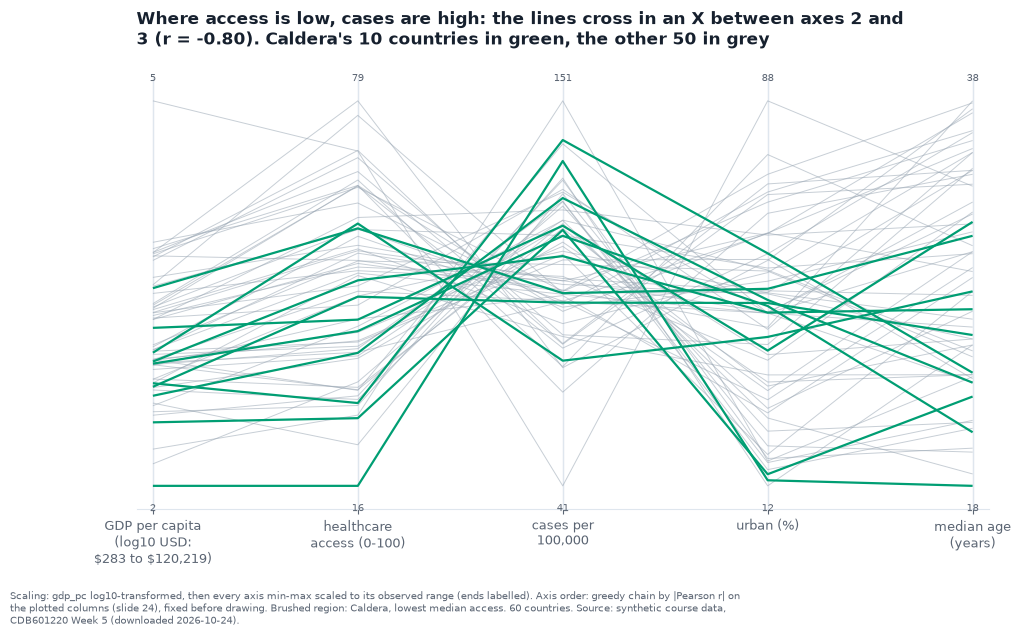

In [4]:
BRUSH = "Caldera"
fig, ax = plt.subplots(figsize=(11, 5.6))
g.pcp(ax, logged, chain, "minmax", highlight=(hi.region == BRUSH).to_numpy(), hl_color=REGION_COLOUR[BRUSH])
# the toolkit prints log10 values (2, 5) at the GDP axis ends, so the USD range goes in the axis label
ax.set_xticks(range(5), ["GDP per capita\n(log10 USD:\n\\$283 to \\$120,219)", "healthcare\naccess (0-100)",
                         "cases per\n100,000", "urban (%)", "median age\n(years)"], fontsize=9)
ax.set_title(textwrap.fill("Where access is low, cases are high: the lines cross in an X between axes 2 and 3 "
                           f"(r = -0.80). {BRUSH}'s 10 countries in green, the other 50 in grey", 80), pad=24)
save_fig(fig, CHARTS / "partD_pcp.png", note=textwrap.fill(
    "Scaling: gdp_pc log10-transformed, then every axis min-max scaled to its observed range (ends labelled). "
    "Axis order: greedy chain by |Pearson r| on the plotted columns (slide 24), fixed before drawing. "
    f"Brushed region: {BRUSH}, lowest median access. 60 countries. {SOURCE}", 150))

**Two relationships you can actually see:**

1. **Access ↔ case rate (axes 2 and 3): negative.** The lines cross in a tight X, r = −0.80. Caldera's
   lines come in low on access and leave high on cases.
2. **GDP ↔ access (axes 1 and 2): positive.** The lines run roughly parallel, r = +0.83 on log GDP. Rich
   countries have better access, which only shows up once GDP is logged.

## D3 · The normalized choropleth

The six-step recipe from slide 50.

In [5]:
feats = g.read_geojson(DATA / "districts.geojson")
dh = pd.read_csv(DATA / "district_health.csv")

# 2. Join, and count what failed
geo = {f["code"] for f in feats}
fail_geo, fail_tab = sorted(geo - set(dh.code)), sorted(set(dh.code) - geo)
print(f"join: {len(geo & set(dh.code))} matched, {len(fail_geo)} polygons without data, {len(fail_tab)} rows without a polygon")

# 3. Normalize
dh["rate"] = dh.cases / dh.population * 1e5
pooled = dh.cases.sum() / dh.population.sum() * 1e5
print(f"national pooled rate {pooled:.1f} per 100,000 from {dh.cases.sum():,} cases")

# 4. Classify: compare the three schemes before choosing
for sch in ("equal", "quantile", "natural"):
    e = g.breaks(dh.rate, sch, 5)
    print(f"  {sch:9s} GVF {g.gvf(dh.rate, e):.3f}  breaks {np.round(e, 1).tolist()}")

# suppression check: the Part B.5 threshold
print(f"smallest district: {dh.population.min():,} people, {dh.cases.min()} cases -> nothing to suppress")

top_rate, top_count = dh.nlargest(3, "rate").code.tolist(), dh.nlargest(3, "cases").code.tolist()
print(f"top 3 by rate {top_rate}, by count {top_count}, overlap {len(set(top_rate) & set(top_count))}; "
      f"r(cases, population) = {dh.cases.corr(dh.population):+.3f}")

join: 24 matched, 0 polygons without data, 0 rows without a polygon
national pooled rate 52.8 per 100,000 from 30,564 cases
  equal     GVF 0.969  breaks [30.4, 39.6, 48.9, 58.1, 67.3, 76.5]
  quantile  GVF 0.908  breaks [30.4, 43.8, 49.8, 54.1, 63.0, 76.5]
  natural   GVF 0.969  breaks [30.4, 33.8, 47.5, 54.4, 64.8, 76.5]
smallest district: 468,000 people, 186 cases -> nothing to suppress
top 3 by rate ['D19', 'D20', 'D21'], by count ['D17', 'D13', 'D09'], overlap 0; r(cases, population) = +0.986


- **Join:** 24 of 24, with **0 failures** either way.
- **Normalize:** cases per 100,000 residents. Pooled national rate **52.8** from **30,564** cases.
- **Classify:** **natural breaks (Jenks)**, five classes. It has the highest goodness of variance fit
  (GVF 0.969, tied with equal interval; quantile 0.908), and the rates genuinely cluster, so class edges
  at the gaps are meaningful here. Unlike case 5, the spread is real (30 to 77, against ±4.5 of Poisson
  noise for a district of 1 M).
- **Suppression:** none needed. The smallest district has 468,000 people and 186 cases, ten times the
  ~43,000 floor from Part B.5.

'charts\\partD_choropleth.png'

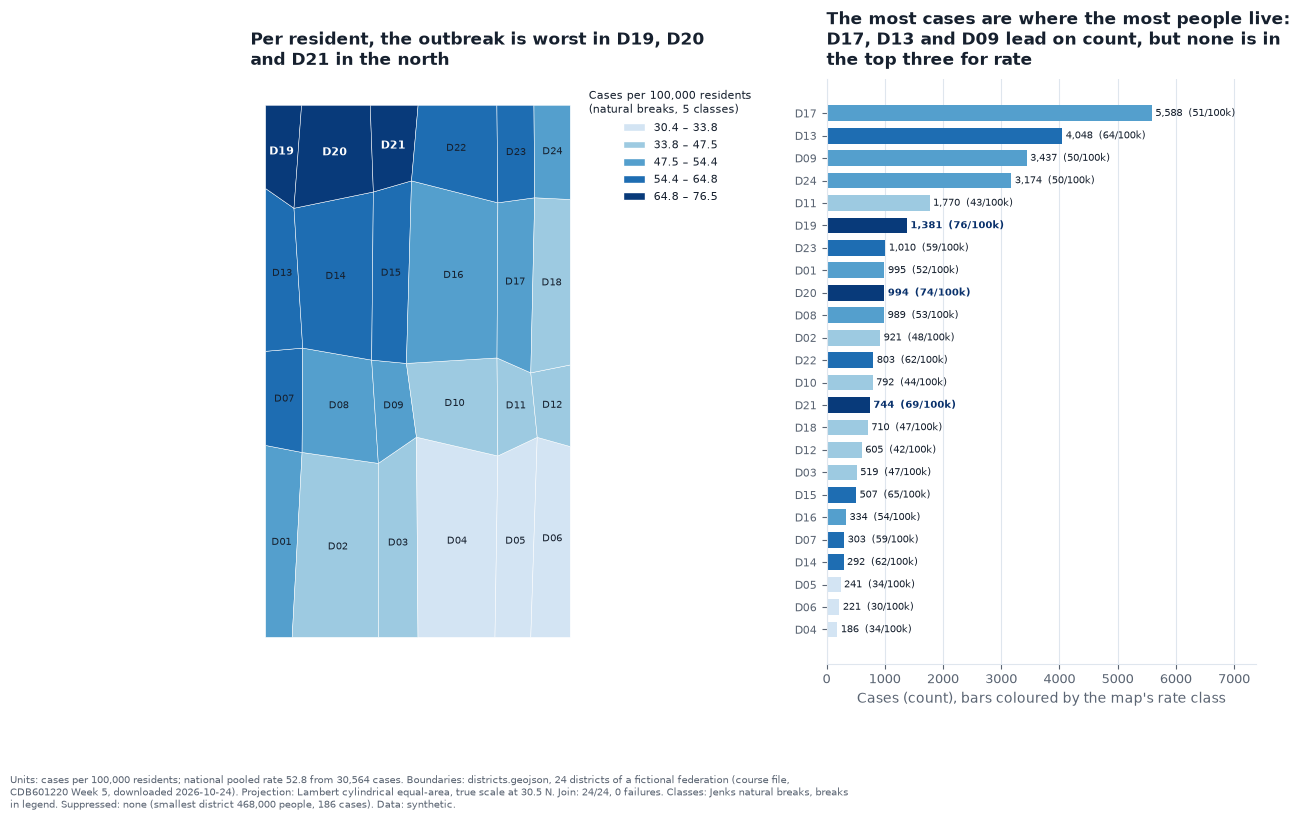

In [6]:
fig = plt.figure(figsize=(14, 7.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], wspace=0.35)
m = fig.add_subplot(gs[0])
edges = g.choropleth(m, feats, dict(zip(dh.code, dh.rate)), "natural", 5, fmt="{:.1f}",
                     legend_title="Cases per 100,000 residents\n(natural breaks, 5 classes)",
                     legend_anchor=(0.98, 1.0))
lat_ts = float(np.mean([p[1] for f in feats for p in f["ring"]]))
for f in feats:
    lon, lat = g.representative_point(f["ring"])
    x, y = g.equal_area_xy([lon], [lat], lat_ts=lat_ts)
    hot = f["code"] in top_rate
    m.text(x[0], y[0], f["code"], ha="center", va="center", fontsize=7 if not hot else 8,
           color="white" if hot else INK, fontweight="bold" if hot else "normal")
m.set_title(textwrap.fill("Per resident, the outbreak is worst in D19, D20 and D21 in the north", 48))

b = fig.add_subplot(gs[1])
srt = dh.sort_values("cases")
cls = g.class_of(srt.rate, edges)
cmap = plt.get_cmap(PALETTE["sequential"])
b.barh(srt.code, srt.cases, color=[cmap(0.18 + 0.78 * c / 4) for c in cls], height=0.7)
for i, (c, v, rt) in enumerate(zip(srt.code, srt.cases, srt.rate)):
    b.text(v + 60, i, f"{v:,}  ({rt:.0f}/100k)", va="center", fontsize=7.5, color=INK if c not in top_rate else "#08306B",
           fontweight="bold" if c in top_rate else "normal")
b.set_xlim(0, srt.cases.max() * 1.32)
b.set_xlabel("Cases (count), bars coloured by the map's rate class")
b.tick_params(axis="y", labelsize=8)
b.grid(axis="y", visible=False)
b.set_title(textwrap.fill("The most cases are where the most people live: D17, D13 and D09 lead on count, "
                          "but none is in the top three for rate", 48))
save_fig(fig, CHARTS / "partD_choropleth.png", note=textwrap.fill(
    "Units: cases per 100,000 residents; national pooled rate 52.8 from 30,564 cases. Boundaries: districts.geojson, "
    "24 districts of a fictional federation (course file, CDB601220 Week 5, downloaded 2026-10-24). Projection: Lambert "
    f"cylindrical equal-area, true scale at {lat_ts:.1f} N. Join: 24/24, 0 failures. Classes: Jenks natural breaks, "
    "breaks in legend. Suppressed: none (smallest district 468,000 people, 186 cases). Data: synthetic.", 170))

The map answers "where is the *risk* per resident?". The bar chart puts the **count** back, coloured by the
same rate class, so it answers "where are the *cases*?" and shows that the two questions have different
answers: the top three by count (D17, D13, D09) sit in the middle and second-highest rate classes, and the top three by rate
(D19, D20, D21) have some of the shortest bars.